# Setup

In [46]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd

In [47]:
# paths
DATASET_ROOT = os.path.join("..", "data", "raw", "StructScan3D")

RGB_DIR = os.path.join(DATASET_ROOT, "rgb")
MASK_DIR = os.path.join(DATASET_ROOT, "masks")
DEPTH_DIR = os.path.join(DATASET_ROOT, "depth") 

# Check if the paths exist
print("Looking for dataset at:", os.path.abspath(DATASET_ROOT))
print("RGB directory exists:", os.path.exists(RGB_DIR))
print("Masks directory exists:", os.path.exists(MASK_DIR))
print("Depth directory exists:", os.path.exists(DEPTH_DIR))

if not os.path.exists(RGB_DIR):
    print("\n⚠️ WARNING: Path not found. Make sure you run this notebook from inside the 'notebooks/' folder.")

Looking for dataset at: c:\Users\Korisnik\kanita\PrivaScrub\data\raw\StructScan3D
RGB directory exists: True
Masks directory exists: True
Depth directory exists: True


# Load splits

In [48]:
def load_split_file(filepath):
    """Reads the txt file and extracts RGB and Mask relative paths."""
    samples = []
    with open(filepath, 'r') as f:
        for line in f:
            parts = line.strip().split('\t') # Split by tab
            if len(parts) >= 2:
                # Store as dictionary for easy access
                samples.append({
                    'rgb': parts[0],   # e.g., 'rgb/rdc_s2_00624.jpg'
                    'mask': parts[1],  # e.g., 'masks/rdc_s2_00624.png'
                    'depth': parts[2] if len(parts) > 2 else None
                })
    return samples

train_file = os.path.join(DATASET_ROOT, "train.txt")
val_file = os.path.join(DATASET_ROOT, "val.txt")

train_samples = load_split_file(train_file)
val_samples = load_split_file(val_file)

print(f"Number of training images: {len(train_samples)}")
print(f"Number of validation images: {len(val_samples)}")
print("Sample training record:", train_samples[0])

Number of training images: 1909
Number of validation images: 683
Sample training record: {'rgb': 'rgb/rdc_s2_00624.jpg', 'mask': 'masks/rdc_s2_00624.png', 'depth': 'depth/rdc_s2_00624.png'}


## load samples

In [75]:
def load_sample(sample, dataset_root):
    """Loads an RGB image and its mask using the paths from the txt file."""
    rgb_path = os.path.join(dataset_root, sample['rgb'])
    mask_path = os.path.join(dataset_root, sample['mask'])
    
    if not os.path.exists(rgb_path) or not os.path.exists(mask_path):
        print(f"Warning: Could not find files for {sample['rgb']}")
        return None, None

    image = cv2.imread(rgb_path)
    if image is not None:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    #mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)  # Load mask without changing its channels
    return image, mask


In [76]:
CLASS_MAPPING = {
    0: "Background/Other",
    1: "Ceiling",      # Updated based on visual proof
    2: "Floor",        
    3: "Door",         
    4: "Window",       
    5: "Wall",         # Updated based on visual proof
    6: "Misc Object"   
}

# Colors: Black, Red, Green, Blue, Yellow, Magenta, Cyan
COLORS = [[0,0,0], [255,0,0], [0,255,0], [0,0,255], [255,255,0], [255,0,255], [0,255,255]]

**IMPORTANT**:
* This mapping is based on visual inspection of the dataset. The original documentation was misleading, and the actual classes were deduced to be inconsistent: sometimes the Window is class 2, sometimes class 6.
* Look at the Notes and conclusions section of the notebook

In [77]:
image, mask = load_sample(train_samples[0], DATASET_ROOT)
np.unique(mask)

array([0, 1, 2, 3, 4, 5], dtype=uint8)

In [81]:
mask = cv2.imread(MASK_DIR, cv2.IMREAD_UNCHANGED)  # Load mask without changing its channels
# If it loads as (height, width, 3), it's an RGB mask.

Visualizing Sample Images


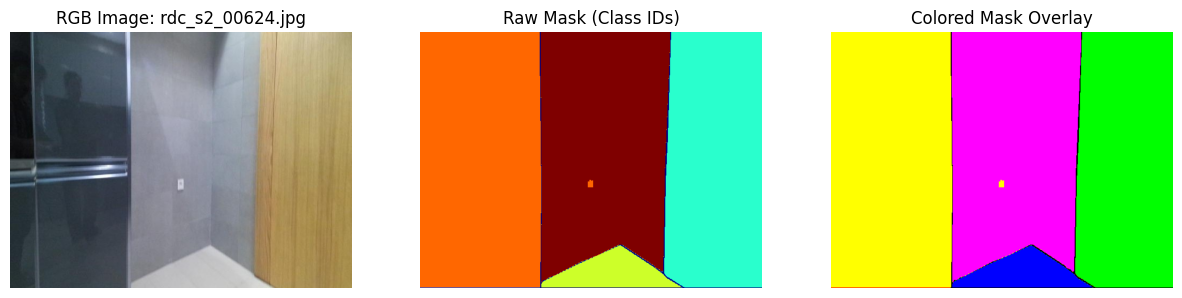

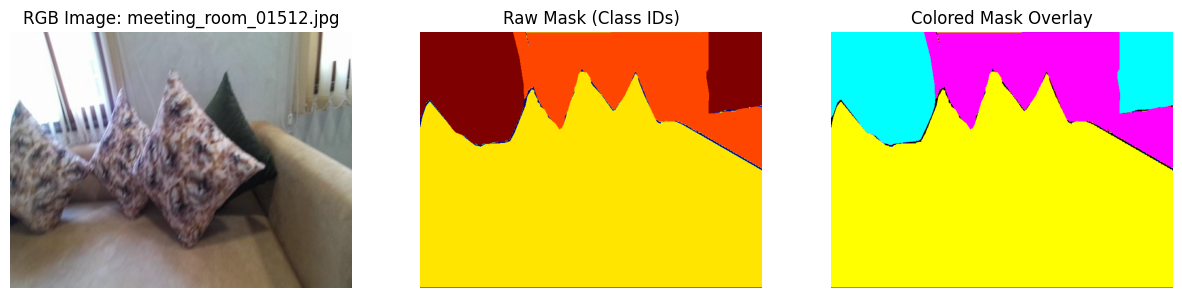

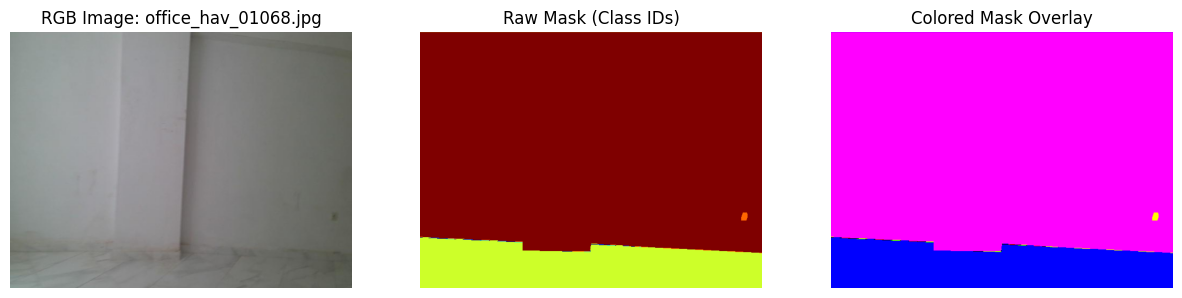

In [82]:
def visualize_sample(sample, dataset_root):
    image, mask = load_sample(sample, dataset_root)
    if image is None:
        return

    colored_mask = np.zeros_like(image)
    for class_id, color in zip(CLASS_MAPPING.keys(), COLORS):
        colored_mask[mask == class_id] = color

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(image)
    axes[0].set_title(f"RGB Image: {os.path.basename(sample['rgb'])}")
    axes[0].axis('off')

    axes[1].imshow(mask, cmap='jet') 
    axes[1].set_title("Raw Mask (Class IDs)")
    axes[1].axis('off')

    axes[2].imshow(colored_mask)
    axes[2].set_title("Colored Mask Overlay")
    axes[2].axis('off')
    plt.show()


print("Visualizing Sample Images")
for sample in train_samples[:3]:
    visualize_sample(sample, DATASET_ROOT)


# data distribution

In [102]:
def calculate_image_counts(samples, dataset_root):
    # Initialize a dictionary to hold counts for IDs 0 through 6
    class_image_counts = {i: 0 for i in range(7)}
    
    # Loop over ALL samples in the split
    for sample in samples:
        _, mask = load_sample(sample, dataset_root)
        if mask is None:
            continue
            
        # Find which classes are present in THIS specific image
        unique_classes = np.unique(mask)
        
        # Increment the count for each class found
        for class_id in unique_classes:
            if class_id in class_image_counts:
                class_image_counts[class_id] += 1
                
    # Convert to DataFrame
    df_counts = pd.DataFrame(list(class_image_counts.items()), columns=['Class_ID', 'Image_Count'])
    
    # Map to your current CLASS_MAPPING to see how it lines up
    df_counts['Current_Guess'] = df_counts['Class_ID'].map(CLASS_MAPPING)
    
    return df_counts.sort_values(by='Class_ID')

print("Number of Images Containing Each Class (Full Training Set)")
image_counts_df = calculate_image_counts(train_samples, DATASET_ROOT)
print(image_counts_df)

Number of Images Containing Each Class (Full Training Set)
   Class_ID  Image_Count     Current_Guess
0         0         1905  Background/Other
1         1         1907           Ceiling
2         2         1856             Floor
3         3         1900              Door
4         4         1908            Window
5         5         1908              Wall
6         6          638       Misc Object


note:
* data card says this: `Class distribution: Ceiling: 549, Door: 528, Floor: 1056, Wall: 1644, Window: 590, Other: 1779.`
* from this output we conclude the dataset is very noisy

In [103]:
def calculate_class_distribution(filenames, sample_size=50):
    all_pixel_counts = {}
    sampled_filenames = np.random.choice(filenames, min(sample_size, len(filenames)), replace=False)
    
    for fname in sampled_filenames:
        _, mask = load_sample(fname, DATASET_ROOT)
        if mask is None:
            continue
            
        unique, counts = np.unique(mask, return_counts=True)
        for class_id, count in zip(unique, counts):
            if class_id not in all_pixel_counts:
                all_pixel_counts[class_id] = 0
            all_pixel_counts[class_id] += count
            
    df_dist = pd.DataFrame(list(all_pixel_counts.items()), columns=['Class_ID', 'Total_Pixels'])
    df_dist['Percentage'] = (df_dist['Total_Pixels'] / df_dist['Total_Pixels'].sum()) * 100
    df_dist['Class_Name'] = df_dist['Class_ID'].map(CLASS_MAPPING)
    
    return df_dist.sort_values(by='Percentage', ascending=False)

print("\n--- Class Distribution (Sampled) ---")
dist_df = calculate_class_distribution(train_filenames)
print(dist_df.sort_values(by='Class_ID', ascending=True))


--- Class Distribution (Sampled) ---
   Class_ID  Total_Pixels  Percentage        Class_Name
0         0         83350    0.542643  Background/Other
1         1        887952    5.780938           Ceiling
2         2       1863782   12.133997             Floor
3         3       1177291    7.664655              Door
4         4        973489    6.337819            Window
5         5       9873842   64.282826              Wall
6         6        500294    3.257122       Misc Object


Deducing Class Mapping visually...


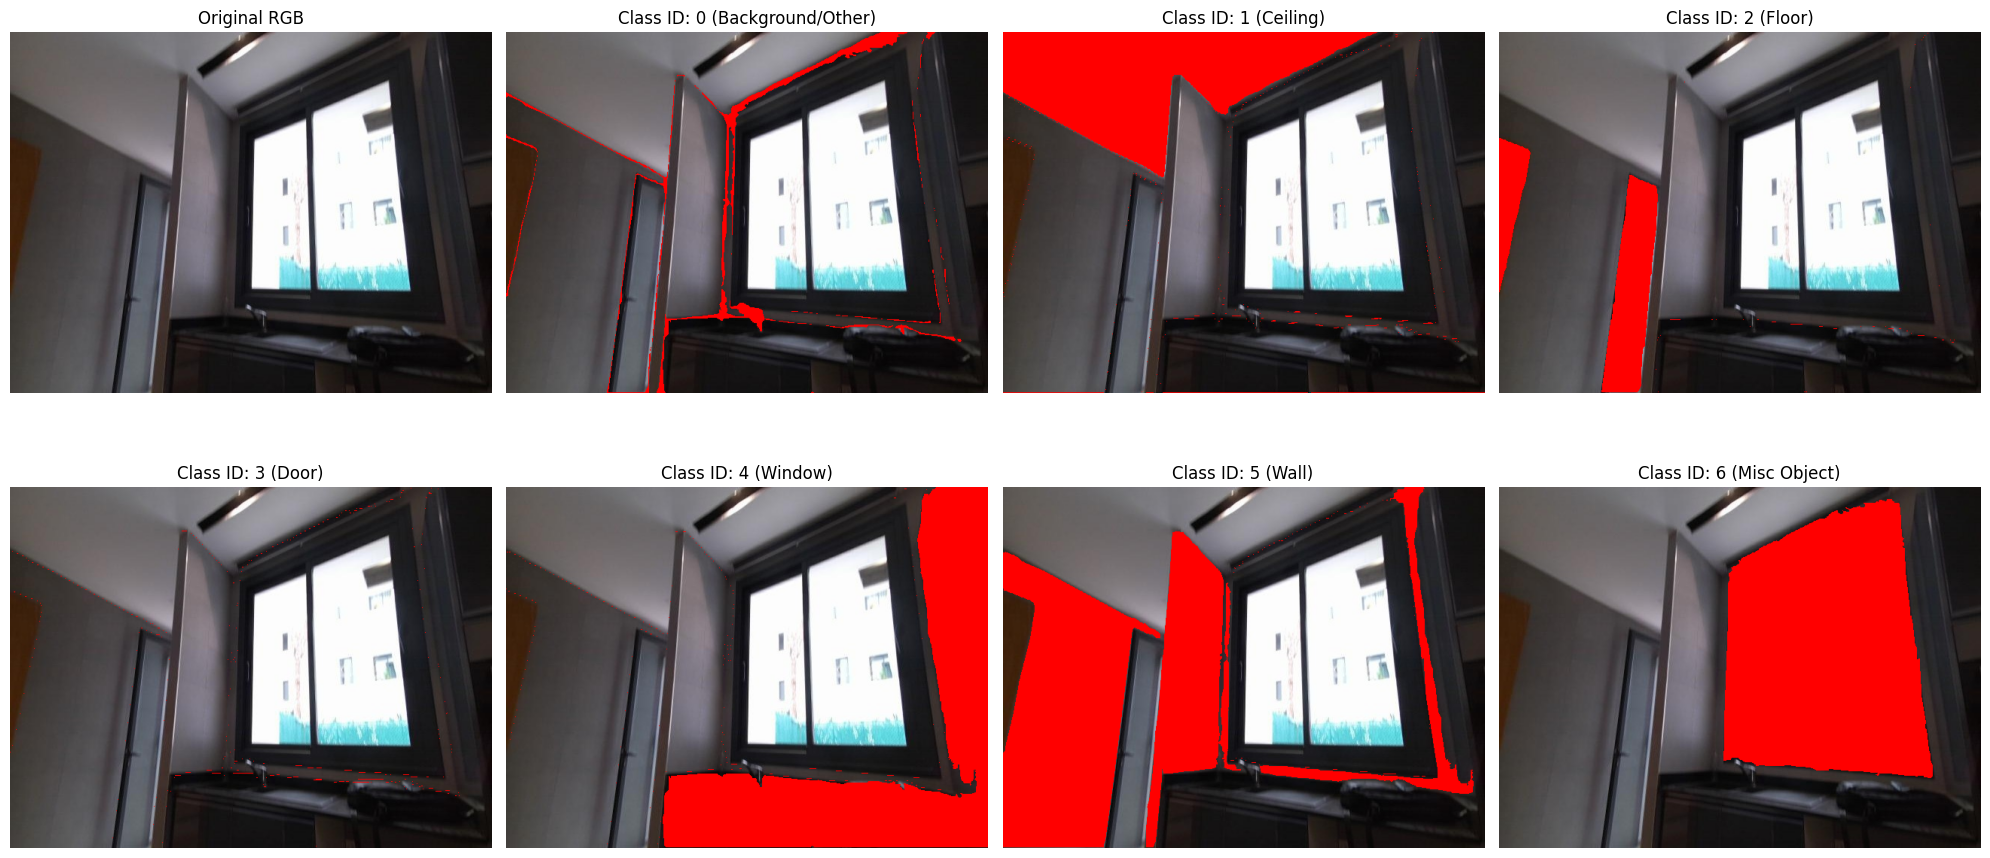

In [ ]:
def deduce_class_mapping(sample, dataset_root):
    image, mask = load_sample(sample, dataset_root)
    if image is None:
        return

    # Find all unique class IDs present in this mask
    unique_classes = np.unique(mask)
    
    # Total plots needed: 1 for original + number of unique classes
    total_plots = len(unique_classes) + 1
    
    # Calculate a safe grid size (2 rows, enough columns)
    cols = (total_plots + 1) // 2
    fig, axes = plt.subplots(2, cols, figsize=(5 * cols, 10))
    axes = axes.flatten() # Flatten to easily iterate over it

    # Plot the original image first
    axes[0].imshow(image)
    axes[0].set_title("Original RGB")
    axes[0].axis('off')

    # Loop through each class and create a highlighted overlay
    for i, class_id in enumerate(unique_classes):
        # Create a copy of the image
        overlay = image.copy()
        
        # Create a boolean mask for this specific class
        class_mask = (mask == class_id)
        
        # Color the class pixels RED (255, 0, 0) so they stand out
        overlay[class_mask] = [255, 0, 0] 
        
        # Plot at index i+1
        axes[i+1].imshow(overlay)
        axes[i+1].set_title(f"Class ID: {class_id} ({CLASS_MAPPING.get(class_id, 'Unknown')})")
        axes[i+1].axis('off')


    # Hide any empty subplots
    for j in range(total_plots, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

# Run this on the 6th training sample
print("Deducing Class Mapping visually...")
deduce_class_mapping(train_samples[5], DATASET_ROOT)

Deducing Class Mapping visually...


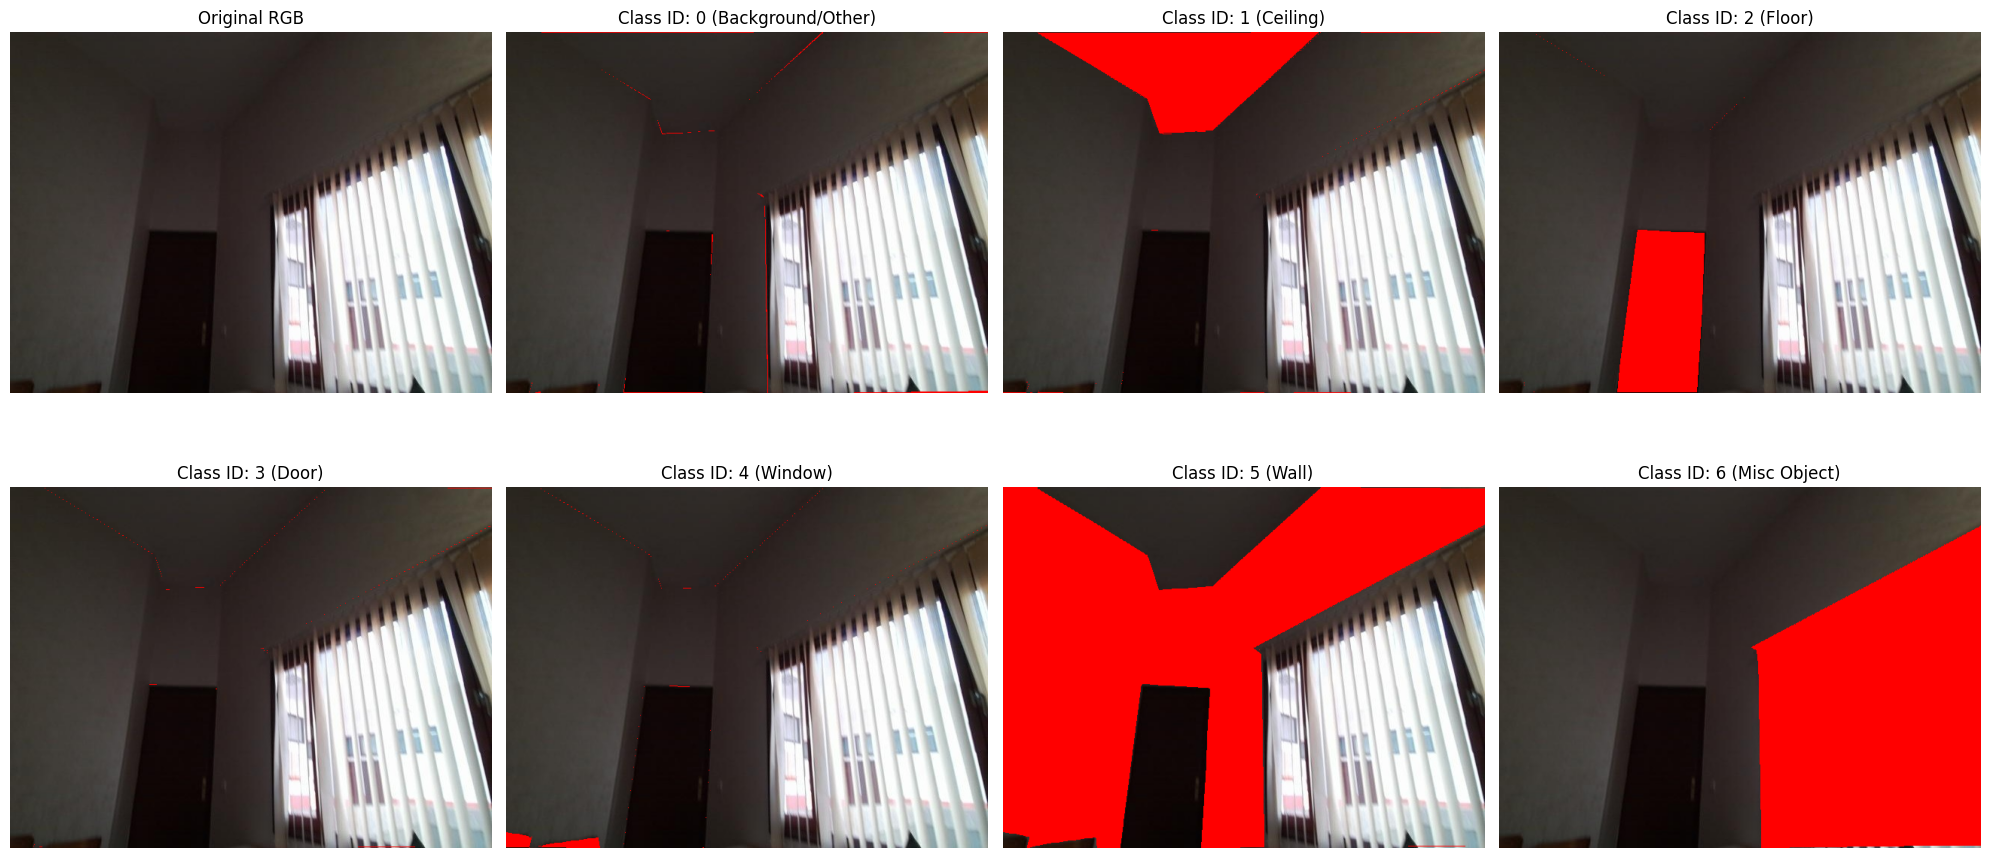

In [ ]:
# Run this on the 41st training sample
print("Deducing Class Mapping visually...")
deduce_class_mapping(train_samples[40], DATASET_ROOT)

Deducing Class Mapping visually...


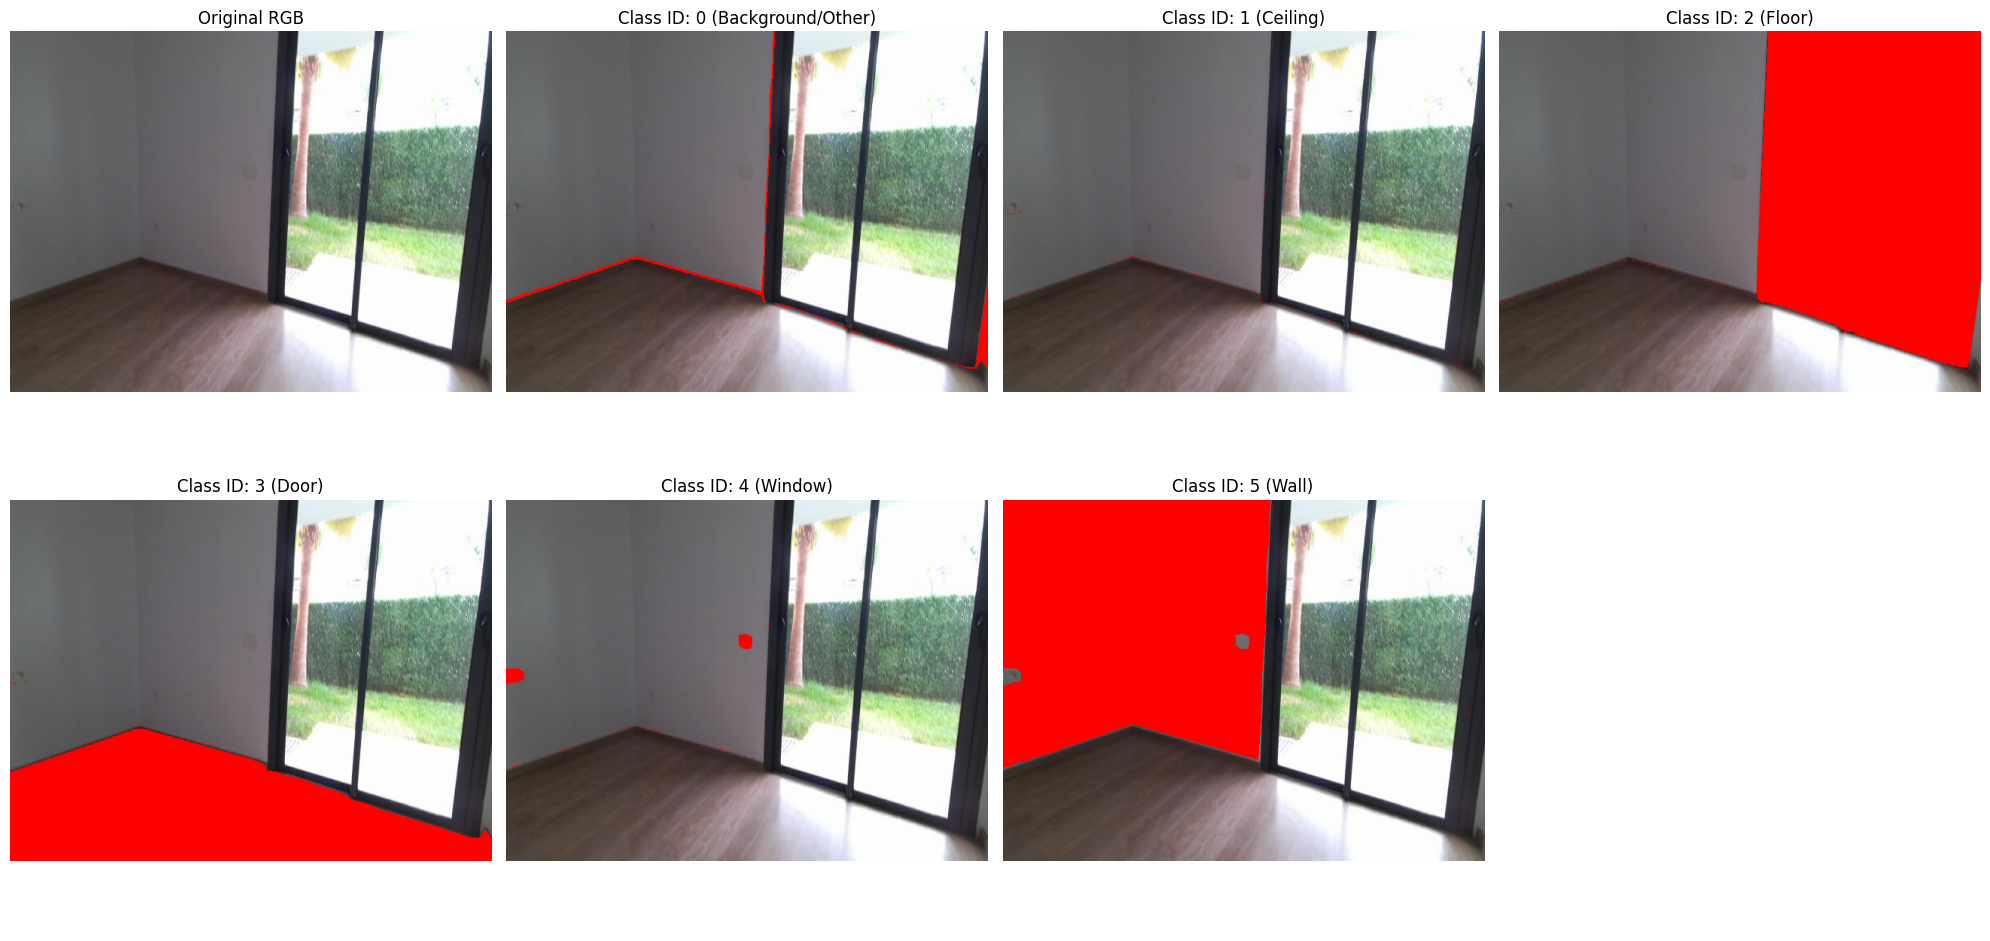

In [104]:
# Run this on the 61st training sample
print("Deducing Class Mapping visually...")
deduce_class_mapping(train_samples[60], DATASET_ROOT)

Deducing Class Mapping visually...


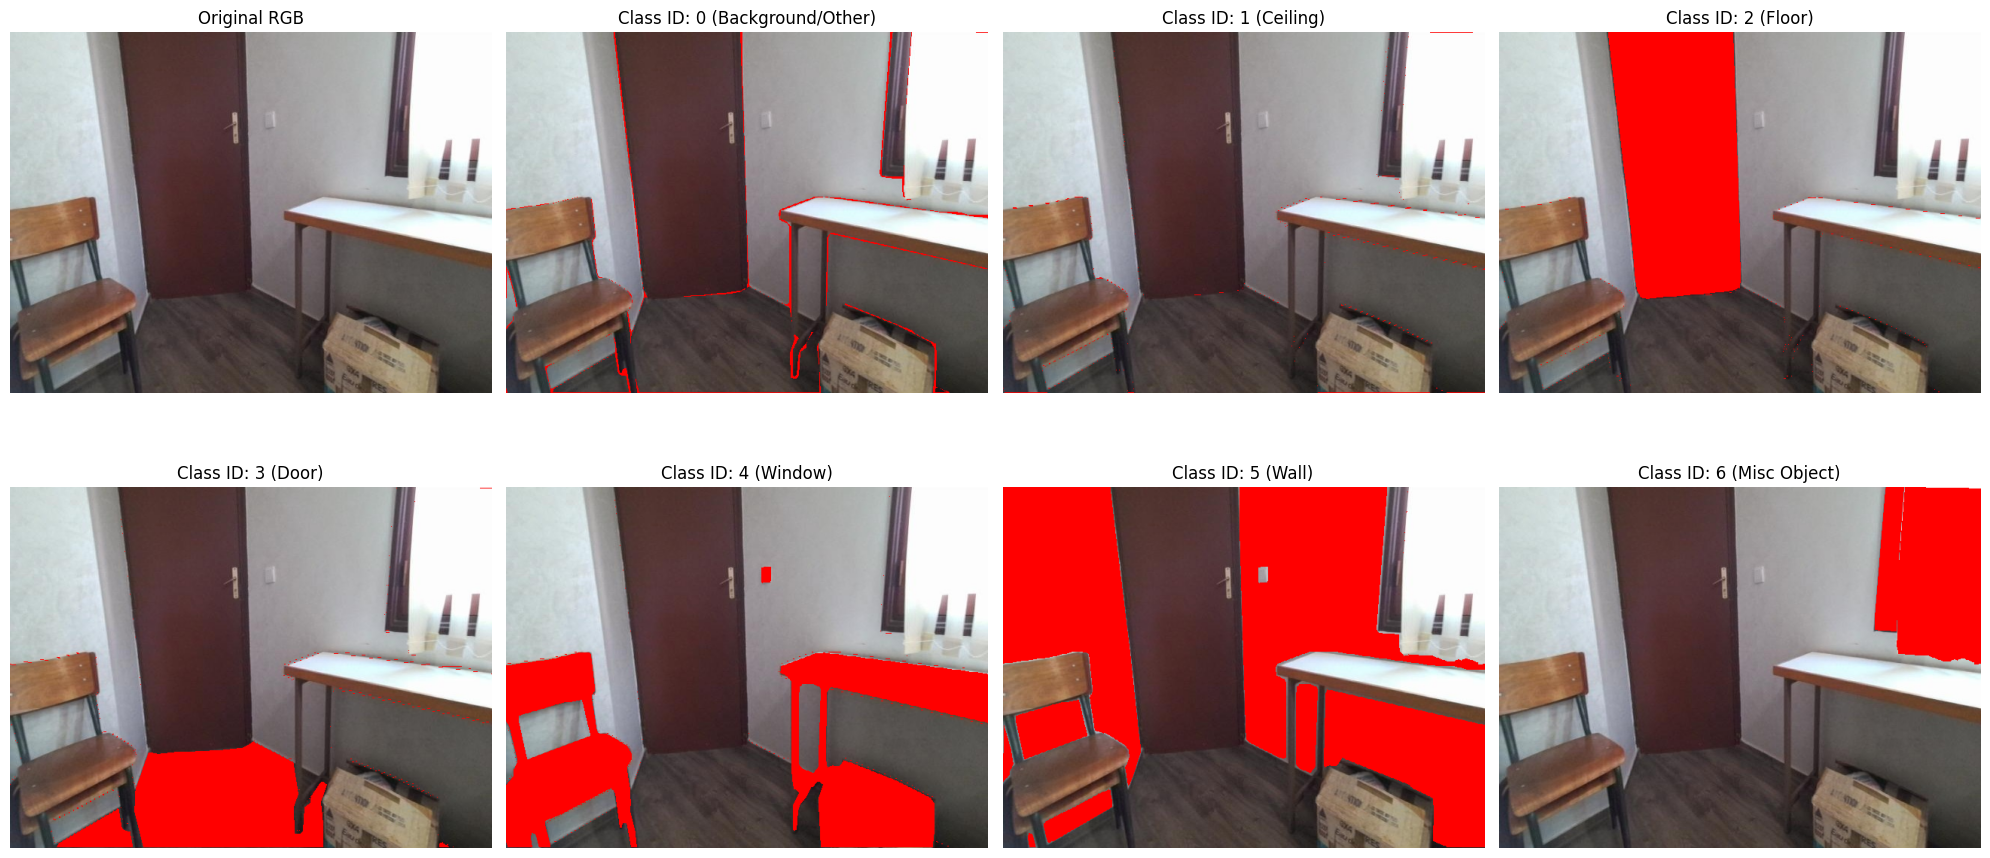

In [108]:
# Run this on the 108th training sample
print("Deducing Class Mapping visually...")
deduce_class_mapping(train_samples[107], DATASET_ROOT)

# Notes and conclusions


From visual inspection of class distribution:
* Labelling is inconsistent because:
    * from smples 41 and 61 we can see that the class `Window` is class 2 in one and class 6 in another sample
    * classes `Ceiling` (or `Wall`) and `Door` are also mixed up a lot
* Because of this class inconsistency, we conclude that **StructScan3D data set is UNUSABLE!**
